# How well calibrated is Polymarket's own BTC 5-minute order book?

*The code was written by an AI assistant (Claude) from my instructions; see [How this was made](../README.md#how-this-was-made).*

**Data period:** 21 March to 5 April 2026 (UTC), 16 days of my live capture (4,544 markets; 21 March and 5 April are partial days).

**Question.** If the UP token trades at 0.62, does the market resolve UP about 62% of the time? Measured by
calibration curves, Brier score (`mean((p - outcome)²)`, lower is better; 0.25 = always 0.5) and WMACE (weighted mean
absolute calibration error, in cents), split by time in the window and by volatility regime (fifths of Binance's
trailing 60 s volatility). The Up token's mid is read directly as P(Up), and calibration is measured at each cent
level of the price, with no binning.

**Important for reading the numbers:** the 12.5 million rows are 100 ms snapshots from 4,544 five-minute windows.
Snapshots within a window are strongly dependent, so the effective sample size is closer to the number of windows
than to the number of rows, and the uncertainty in every number below is much larger than the row counts suggest.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 10,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

## 1. Paths

In [2]:
BASE = Path('data')   # folder with clob_bbo/, binance_spot/ and windows.csv

def find_feed(base, name):
    """Try common subfolder layouts to find a data feed."""
    candidates = [
        base / 'server_data' / name,
        base / name,
        base / 'data' / name,
    ]
    for c in candidates:
        if c.exists():
            print(f'  Found {name} at: {c}')
            return c
    raise FileNotFoundError(f"Cannot find '{name}' under {base}.\nTried:\n" + '\n'.join(str(c) for c in candidates))

CLOB_BBO_DIR = find_feed(BASE, 'clob_bbo')
BN_SPOT_DIR  = find_feed(BASE, 'binance_spot')
WINDOWS_CSV  = find_feed(BASE, 'windows.csv')

print(f'\nBBO files:  {len(list(CLOB_BBO_DIR.glob("*.csv*")))}')
print(f'BN files:   {len(list(BN_SPOT_DIR.glob("*.csv*")))}')

  Found clob_bbo at: data/clob_bbo
  Found binance_spot at: data/binance_spot
  Found windows.csv at: data/windows.csv

BBO files:  380
BN files:   391


## 2. Load Windows (Ground Truth)

In [3]:
windows = pd.read_csv(WINDOWS_CSV)
windows['outcome'] = (windows['outcome'] == 'UP').astype(np.int8)
windows = windows.sort_values('window_ts').reset_index(drop=True)
windows['date'] = pd.to_datetime(windows['window_ts'], unit='s').dt.date

print(f'Total windows:  {len(windows):,}')
print(f'Date range:     {windows["date"].min()} → {windows["date"].max()}')
print(f'Days:           {windows["date"].nunique()}')
print(f'UP fraction:    {windows["outcome"].mean():.4f}')

Total windows:  4,698
Date range:     2026-03-20 → 2026-04-05
Days:           17
UP fraction:    0.5011


## 3. Load CLOB BBO

> **BBO tracks YES token.** `mid = (best_bid + best_ask) / 2` = P(UP) directly. Do NOT invert.

In [4]:
bbo_dfs = []
for f in sorted(CLOB_BBO_DIR.glob('*.csv*')):
    try:
        bbo_dfs.append(pd.read_csv(f, on_bad_lines='skip'))
    except Exception as e:
        print(f'  Skipped {f.name}: {e}')

bbo_raw = pd.concat(bbo_dfs, ignore_index=True)
print(f'Raw rows: {len(bbo_raw):,}')
print(f'Columns:  {list(bbo_raw.columns)}')

# Parse
bbo_raw['local_ms']  = pd.to_numeric(bbo_raw['local_ms'],  errors='coerce')
bbo_raw['best_bid']  = pd.to_numeric(bbo_raw['best_bid'],  errors='coerce')
bbo_raw['best_ask']  = pd.to_numeric(bbo_raw['best_ask'],  errors='coerce')
bbo_raw = bbo_raw.dropna(subset=['local_ms', 'best_bid', 'best_ask'])
bbo_raw = bbo_raw.sort_values('local_ms', kind='stable').drop_duplicates(subset=['local_ms']).reset_index(drop=True)

# Derived columns — YES token, no inversion
bbo_raw['mid']    = (bbo_raw['best_bid'] + bbo_raw['best_ask']) / 2
bbo_raw['spread'] = bbo_raw['best_ask'] - bbo_raw['best_bid']

# Sanity filter: valid probability range, positive spread
bbo_raw = bbo_raw[
    (bbo_raw['best_bid'] >= 0.01) &
    (bbo_raw['best_ask'] <= 0.99) &
    (bbo_raw['best_bid'] < bbo_raw['best_ask'])
].reset_index(drop=True)

print(f'Clean rows: {len(bbo_raw):,}')
print(f'Mid range:  {bbo_raw["mid"].min():.3f} → {bbo_raw["mid"].max():.3f}')
print(f'Spread:     median={bbo_raw["spread"].median():.4f}  mean={bbo_raw["spread"].mean():.4f}')

Raw rows: 13,516,253
Columns:  ['local_ms', 'server_ms', 'best_bid', 'bid_size', 'best_ask', 'ask_size', 'asset_id']
Clean rows: 12,513,235
Mid range:  0.010 → 0.990
Spread:     median=0.0100  mean=0.0120


## 4. Join BBO → Windows

Assign each BBO tick to its window and compute `t_rem`.

> `t_rem = (window_ts + 300) − (local_ms / 1000)` — must be in [1, 300]

In [5]:
bbo_times_s = bbo_raw['local_ms'].values / 1000.0

win_ts       = windows['window_ts'].values   # seconds
win_outcomes = windows['outcome'].values
win_dates    = windows['date'].values

# Find the last window that started at or before each tick
idx = np.searchsorted(win_ts, bbo_times_s, side='right') - 1

valid = (idx >= 0) & (idx < len(win_ts))
idx_c = np.where(valid, idx, 0)

win_end  = win_ts[idx_c] + 300
t_rem    = win_end - bbo_times_s

# Tick must be inside the window (t_rem in [1, 300])
valid = valid & (t_rem >= 1) & (t_rem <= 300)

bbo = bbo_raw[valid].copy()
bbo['window_ts'] = win_ts[idx_c[valid]]
bbo['outcome']   = win_outcomes[idx_c[valid]]
bbo['t_rem']     = t_rem[valid]
bbo['date']      = win_dates[idx_c[valid]]

# Phase labels: Early = 200 s or more left, Mid = 100 to 200 s, Late = under 100 s
bbo['phase'] = pd.cut(
    bbo['t_rem'],
    bins=[0, 100, 200, 301],
    labels=['Late', 'Mid', 'Early'],
    right=False
)

print(f'Joined rows:      {len(bbo):,}')
print(f'Windows covered:  {bbo["window_ts"].nunique():,}')
print(f'Date range:       {bbo["date"].min()} → {bbo["date"].max()}')
print(f'Phase counts:\n{bbo["phase"].value_counts().sort_index()}')

Joined rows:      12,506,720
Windows covered:  4,544
Date range:       2026-03-21 → 2026-04-05
Phase counts:
phase
Late     3569476
Mid      4458471
Early    4478773
Name: count, dtype: int64


## 5. Volatility Regime (60s Rolling RV from BN Spot)

In [6]:
bn_dfs = []
for f in sorted(BN_SPOT_DIR.glob('*.csv*')):
    try:
        df = pd.read_csv(f, usecols=['local_ms', 'price'], on_bad_lines='skip')
        bn_dfs.append(df)
    except Exception:
        try:
            df = pd.read_csv(f, on_bad_lines='skip')
            bn_dfs.append(df[['local_ms', 'price']])
        except Exception as e:
            print(f'  Skipped {f.name}: {e}')

bn = pd.concat(bn_dfs, ignore_index=True)
bn['local_ms'] = pd.to_numeric(bn['local_ms'], errors='coerce')
bn['price']    = pd.to_numeric(bn['price'],    errors='coerce')

# Fix microsecond timestamps (16 digits) if present
if bn['local_ms'].dropna().max() > 1e15:
    print('  Detected microsecond timestamps — dividing by 1000')
    bn['local_ms'] = bn['local_ms'] // 1000

bn = bn.dropna().sort_values('local_ms', kind='stable').reset_index(drop=True)   # stable: same-millisecond trades keep their order
print(f'BN rows: {len(bn):,}')

# Resample to 1-second bars (last price per second)
bn['ts_s'] = (bn['local_ms'] // 1000).astype(np.int64)
bn_1s = bn.groupby('ts_s')['price'].last().reset_index()
bn_1s = bn_1s.sort_values('ts_s').reset_index(drop=True)

# 60s rolling RV = rolling std of log returns
bn_1s['log_ret'] = np.log(bn_1s['price'] / bn_1s['price'].shift(1))
bn_1s['rv_60s']  = bn_1s['log_ret'].rolling(60, min_periods=10).std()

# Quintile labels — rank within this dataset
valid_rv = bn_1s['rv_60s'].dropna()
q_edges  = np.percentile(valid_rv, [0, 20, 40, 60, 80, 100])
bn_1s['rv_q'] = pd.cut(
    bn_1s['rv_60s'],
    bins=q_edges,
    labels=['Q1 Quiet', 'Q2', 'Q3', 'Q4', 'Q5 Active'],
    include_lowest=True
)

print(f'RV 1s bars: {len(bn_1s):,}')
print(f'RV stats:\n{bn_1s["rv_60s"].describe().round(6)}')

BN rows: 54,658,892
RV 1s bars: 1,225,538
RV stats:
count    1.225528e+06
mean     5.400000e-05
std      4.400000e-05
min      0.000000e+00
25%      2.800000e-05
50%      4.500000e-05
75%      6.900000e-05
max      1.515000e-03
Name: rv_60s, dtype: float64


In [7]:
# Assign RV to each BBO tick from the last full second before it. The bar of the tick's own second holds that second's
# last price, which can come after the tick, so it is not used.
bbo_ts_s = (bbo['local_ms'].values // 1000).astype(np.int64)
bn_ts_s  = bn_1s['ts_s'].values
bn_rv    = bn_1s['rv_60s'].values
bn_rv_q  = bn_1s['rv_q'].values

rv_idx = np.searchsorted(bn_ts_s, bbo_ts_s, side='left') - 1
rv_idx = np.clip(rv_idx, 0, len(bn_ts_s) - 1)

bbo['rv_60s'] = bn_rv[rv_idx]
bbo['rv_q']   = bn_rv_q[rv_idx]

print(f'RV NaN fraction: {bbo["rv_60s"].isna().mean():.3f}')
print(f'Regime counts:\n{bbo["rv_q"].value_counts().sort_index()}')

RV NaN fraction: 0.000
Regime counts:
rv_q
Q1 Quiet     2920920
Q2           2657003
Q3           2505286
Q4           2353857
Q5 Active    2069654
Name: count, dtype: int64


## 6. Calibration Functions

No binning. For each exact cent level, count observations and sum outcomes.

In [8]:
def calibration_table(df, price_col):
    """
    For each unique cent-level price, compute:
      count      = number of BBO ticks at that level
      sum_up     = ticks where window resolved UP
      actual_p   = sum_up / count  (true probability)
      error      = actual_p - price (positive = market underpriced UP)
    """
    p = np.round(df[price_col].values, 2)
    y = df['outcome'].values.astype(float)
    result = (
        pd.DataFrame({'price': p, 'outcome': y})
        .groupby('price')['outcome']
        .agg(['count', 'sum'])
        .rename(columns={'sum': 'sum_up'})
        .reset_index()
    )
    result['actual_p'] = result['sum_up'] / result['count']
    result['error']    = result['actual_p'] - result['price']
    return result

def brier(df, price_col):
    p = df[price_col].values.astype(float)
    y = df['outcome'].values.astype(float)
    return np.mean((p - y) ** 2)

def wmace(df, price_col):
    """Weighted Mean Absolute Calibration Error — weighted by count per level."""
    ct = calibration_table(df, price_col)
    w = ct['count'] / ct['count'].sum()
    return (w * np.abs(ct['error'])).sum()

## 7. Overall Calibration — Bid, Mid, Ask

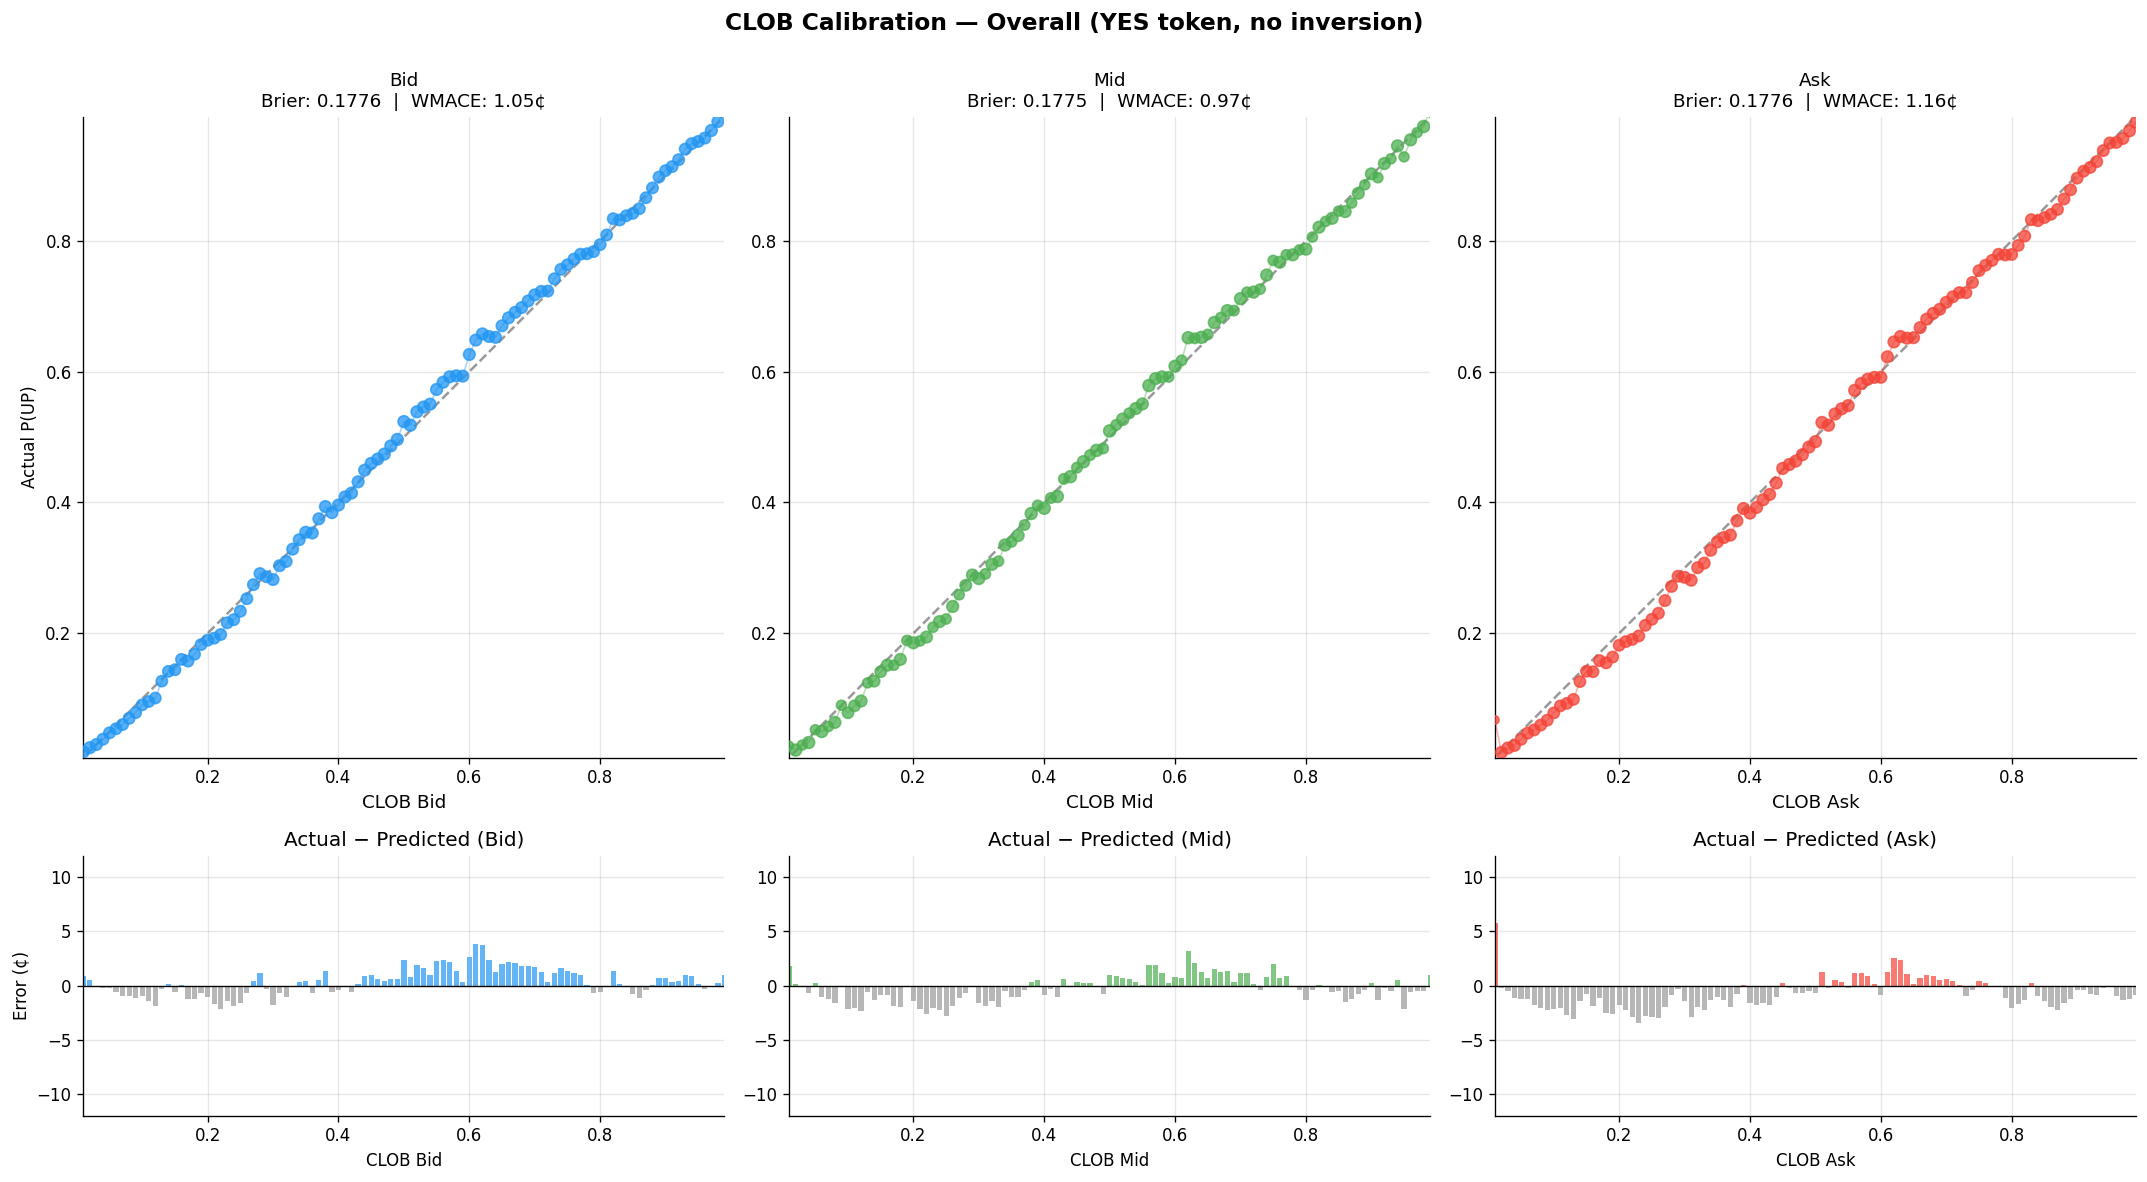


=== SUMMARY ===
Bid       Brier=0.1776  WMACE=1.05¢
Mid       Brier=0.1775  WMACE=0.97¢
Ask       Brier=0.1776  WMACE=1.16¢


In [9]:
cols   = ['best_bid', 'mid', 'best_ask']
labels = ['Bid', 'Mid', 'Ask']
colors = ['#2196F3', '#4CAF50', '#F44336']

fig, axes = plt.subplots(2, 3, figsize=(18, 10),
                         gridspec_kw={'height_ratios': [3, 1]})
fig.suptitle('CLOB Calibration — Overall (YES token, no inversion)', fontsize=14, fontweight='bold')

for j, (col, lbl, col_) in enumerate(zip(cols, labels, colors)):
    ct = calibration_table(bbo, col)
    bs = brier(bbo, col)
    wm = wmace(bbo, col)

    ax = axes[0, j]
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, lw=1.5, label='Perfect')
    # Marker size proportional to log(count)
    sz = np.log1p(ct['count']) * 4
    ax.scatter(ct['price'], ct['actual_p'], s=sz, c=col_, alpha=0.75, zorder=5)
    ax.plot(ct['price'], ct['actual_p'], c=col_, alpha=0.4, lw=1)
    ax.set_xlim(0.01, 0.99); ax.set_ylim(0.01, 0.99)
    ax.set_xlabel(f'CLOB {lbl}', fontsize=11)
    ax.set_ylabel('Actual P(UP)' if j == 0 else '')
    ax.set_title(f'{lbl}\nBrier: {bs:.4f}  |  WMACE: {wm*100:.2f}¢', fontsize=11)
    ax.set_aspect('equal')

    # Error bar (actual − predicted)
    ax2 = axes[1, j]
    ax2.bar(ct['price'], ct['error'] * 100, width=0.008,
            color=[col_ if e >= 0 else '#999' for e in ct['error']], alpha=0.7)
    ax2.axhline(0, color='black', lw=0.8)
    ax2.set_xlabel(f'CLOB {lbl}')
    ax2.set_ylabel('Error (¢)' if j == 0 else '')
    ax2.set_xlim(0.01, 0.99)
    ax2.set_ylim(-12, 12)
    ax2.set_title(f'Actual − Predicted ({lbl})')

plt.tight_layout()
plt.savefig('../figures/02_calibration_overall.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n=== SUMMARY ===')
for col, lbl in zip(cols, labels):
    print(f'{lbl:8s}  Brier={brier(bbo, col):.4f}  WMACE={wmace(bbo, col)*100:.2f}¢')

### Are the deviations more than noise?

The same calibration curve for the mid, with 95% intervals from resampling whole windows (`N_BOOT` times), because
snapshots inside one window are not independent and neighbouring price levels share windows. Two groups are also pooled:
mids below 0.40 and mids from 0.50 to 0.80, where the deviations in the figure above have the same sign.

Mid levels from 0.05 to 0.95: 91
  interval above zero (outcome more often UP than the price): 1
  interval below zero (outcome less often UP than the price): 6
  median interval width: 4.8 c
Pooled groups
  mid 0.00 to 0.40: outcome minus price -1.15 c   (95% interval -2.49 to +0.22)
  mid 0.50 to 0.80: outcome minus price +1.09 c   (95% interval -0.66 to +2.66)


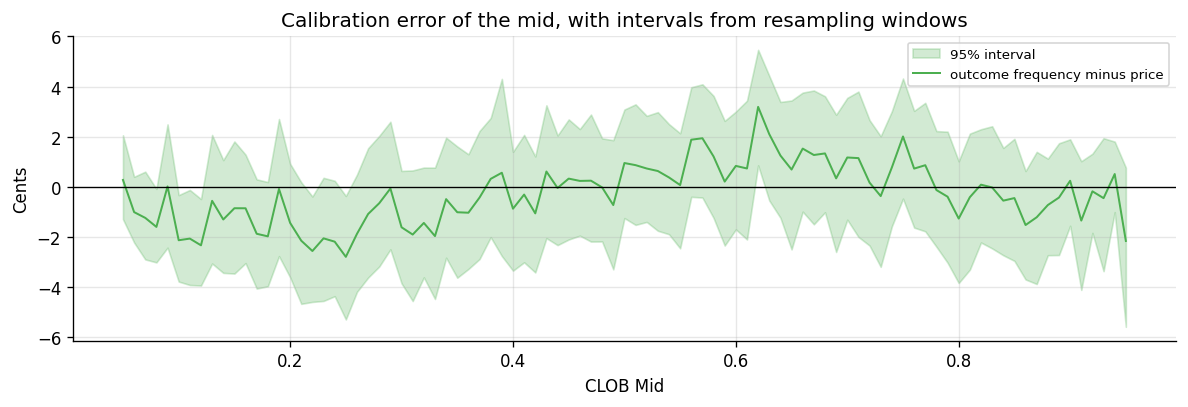

In [10]:
N_BOOT, SEED = 1000, 7
w_idx, w_ids = pd.factorize(bbo['window_ts'])
W = len(w_ids)
lvl = np.round(np.round(bbo['mid'].values, 2) * 100).astype(np.int64)     # the same cent levels as calibration_table
y = bbo['outcome'].values.astype(float)

def per_window(weights):
    # Sum per window and cent level: shape (windows, 101)
    return np.bincount(w_idx * 101 + lvl, weights=weights, minlength=W * 101).reshape(W, 101)

cnt, ups = per_window(np.ones(len(bbo))), per_window(y)
rng = np.random.default_rng(SEED)
BOOT_W = np.stack([np.bincount(rng.integers(0, W, W), minlength=W) for _ in range(N_BOOT)]).astype(np.float64)
b_cnt, b_ups = BOOT_W @ cnt, BOOT_W @ ups                                   # (N_BOOT, 101)
price = np.arange(101) / 100

with np.errstate(invalid='ignore', divide='ignore'):
    err = ups.sum(0) / cnt.sum(0) - price
    b_err = b_ups / b_cnt - price
lo, hi = np.nanpercentile(b_err, 2.5, axis=0), np.nanpercentile(b_err, 97.5, axis=0)
cal_ci = pd.DataFrame({'price': price, 'count': cnt.sum(0).astype(int), 'windows': (cnt > 0).sum(0),
                       'error_c': err * 100, 'lo_c': lo * 100, 'hi_c': hi * 100})
cal_ci = cal_ci[cal_ci['count'] > 0]
cal_ci.to_csv('calibration_mid_intervals.csv', index=False)

used = cal_ci[(cal_ci['price'] >= 0.05) & (cal_ci['price'] <= 0.95)]
print(f'Mid levels from 0.05 to 0.95: {len(used)}')
print(f'  interval above zero (outcome more often UP than the price): {(used["lo_c"] > 0).sum()}')
print(f'  interval below zero (outcome less often UP than the price): {(used["hi_c"] < 0).sum()}')
print(f'  median interval width: {(used["hi_c"] - used["lo_c"]).median():.1f} c')

def pooled(lo_p, hi_p):
    k = (price >= lo_p - 1e-9) & (price < hi_p - 1e-9)
    num = lambda c, u: u[..., k].sum(-1) - (c[..., k] * price[k]).sum(-1)
    est = num(cnt.sum(0), ups.sum(0)) / cnt.sum(0)[k].sum()
    draws = num(b_cnt, b_ups) / b_cnt[:, k].sum(1)
    a, z = np.percentile(draws, [2.5, 97.5])
    print(f'  mid {lo_p:.2f} to {hi_p:.2f}: outcome minus price {est * 100:+.2f} c   (95% interval {a * 100:+.2f} to {z * 100:+.2f})')

print('Pooled groups')
pooled(0.0, 0.40)
pooled(0.50, 0.80)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.fill_between(used['price'], used['lo_c'], used['hi_c'], color='#4CAF50', alpha=0.25, label='95% interval')
ax.plot(used['price'], used['error_c'], color='#4CAF50', lw=1.2, label='outcome frequency minus price')
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('CLOB Mid'); ax.set_ylabel('Cents'); ax.legend(fontsize=8)
ax.set_title('Calibration error of the mid, with intervals from resampling windows')
plt.tight_layout(); plt.savefig('../figures/02_calibration_mid_intervals.png', dpi=150, bbox_inches='tight'); plt.show()

## 8. Calibration by Day

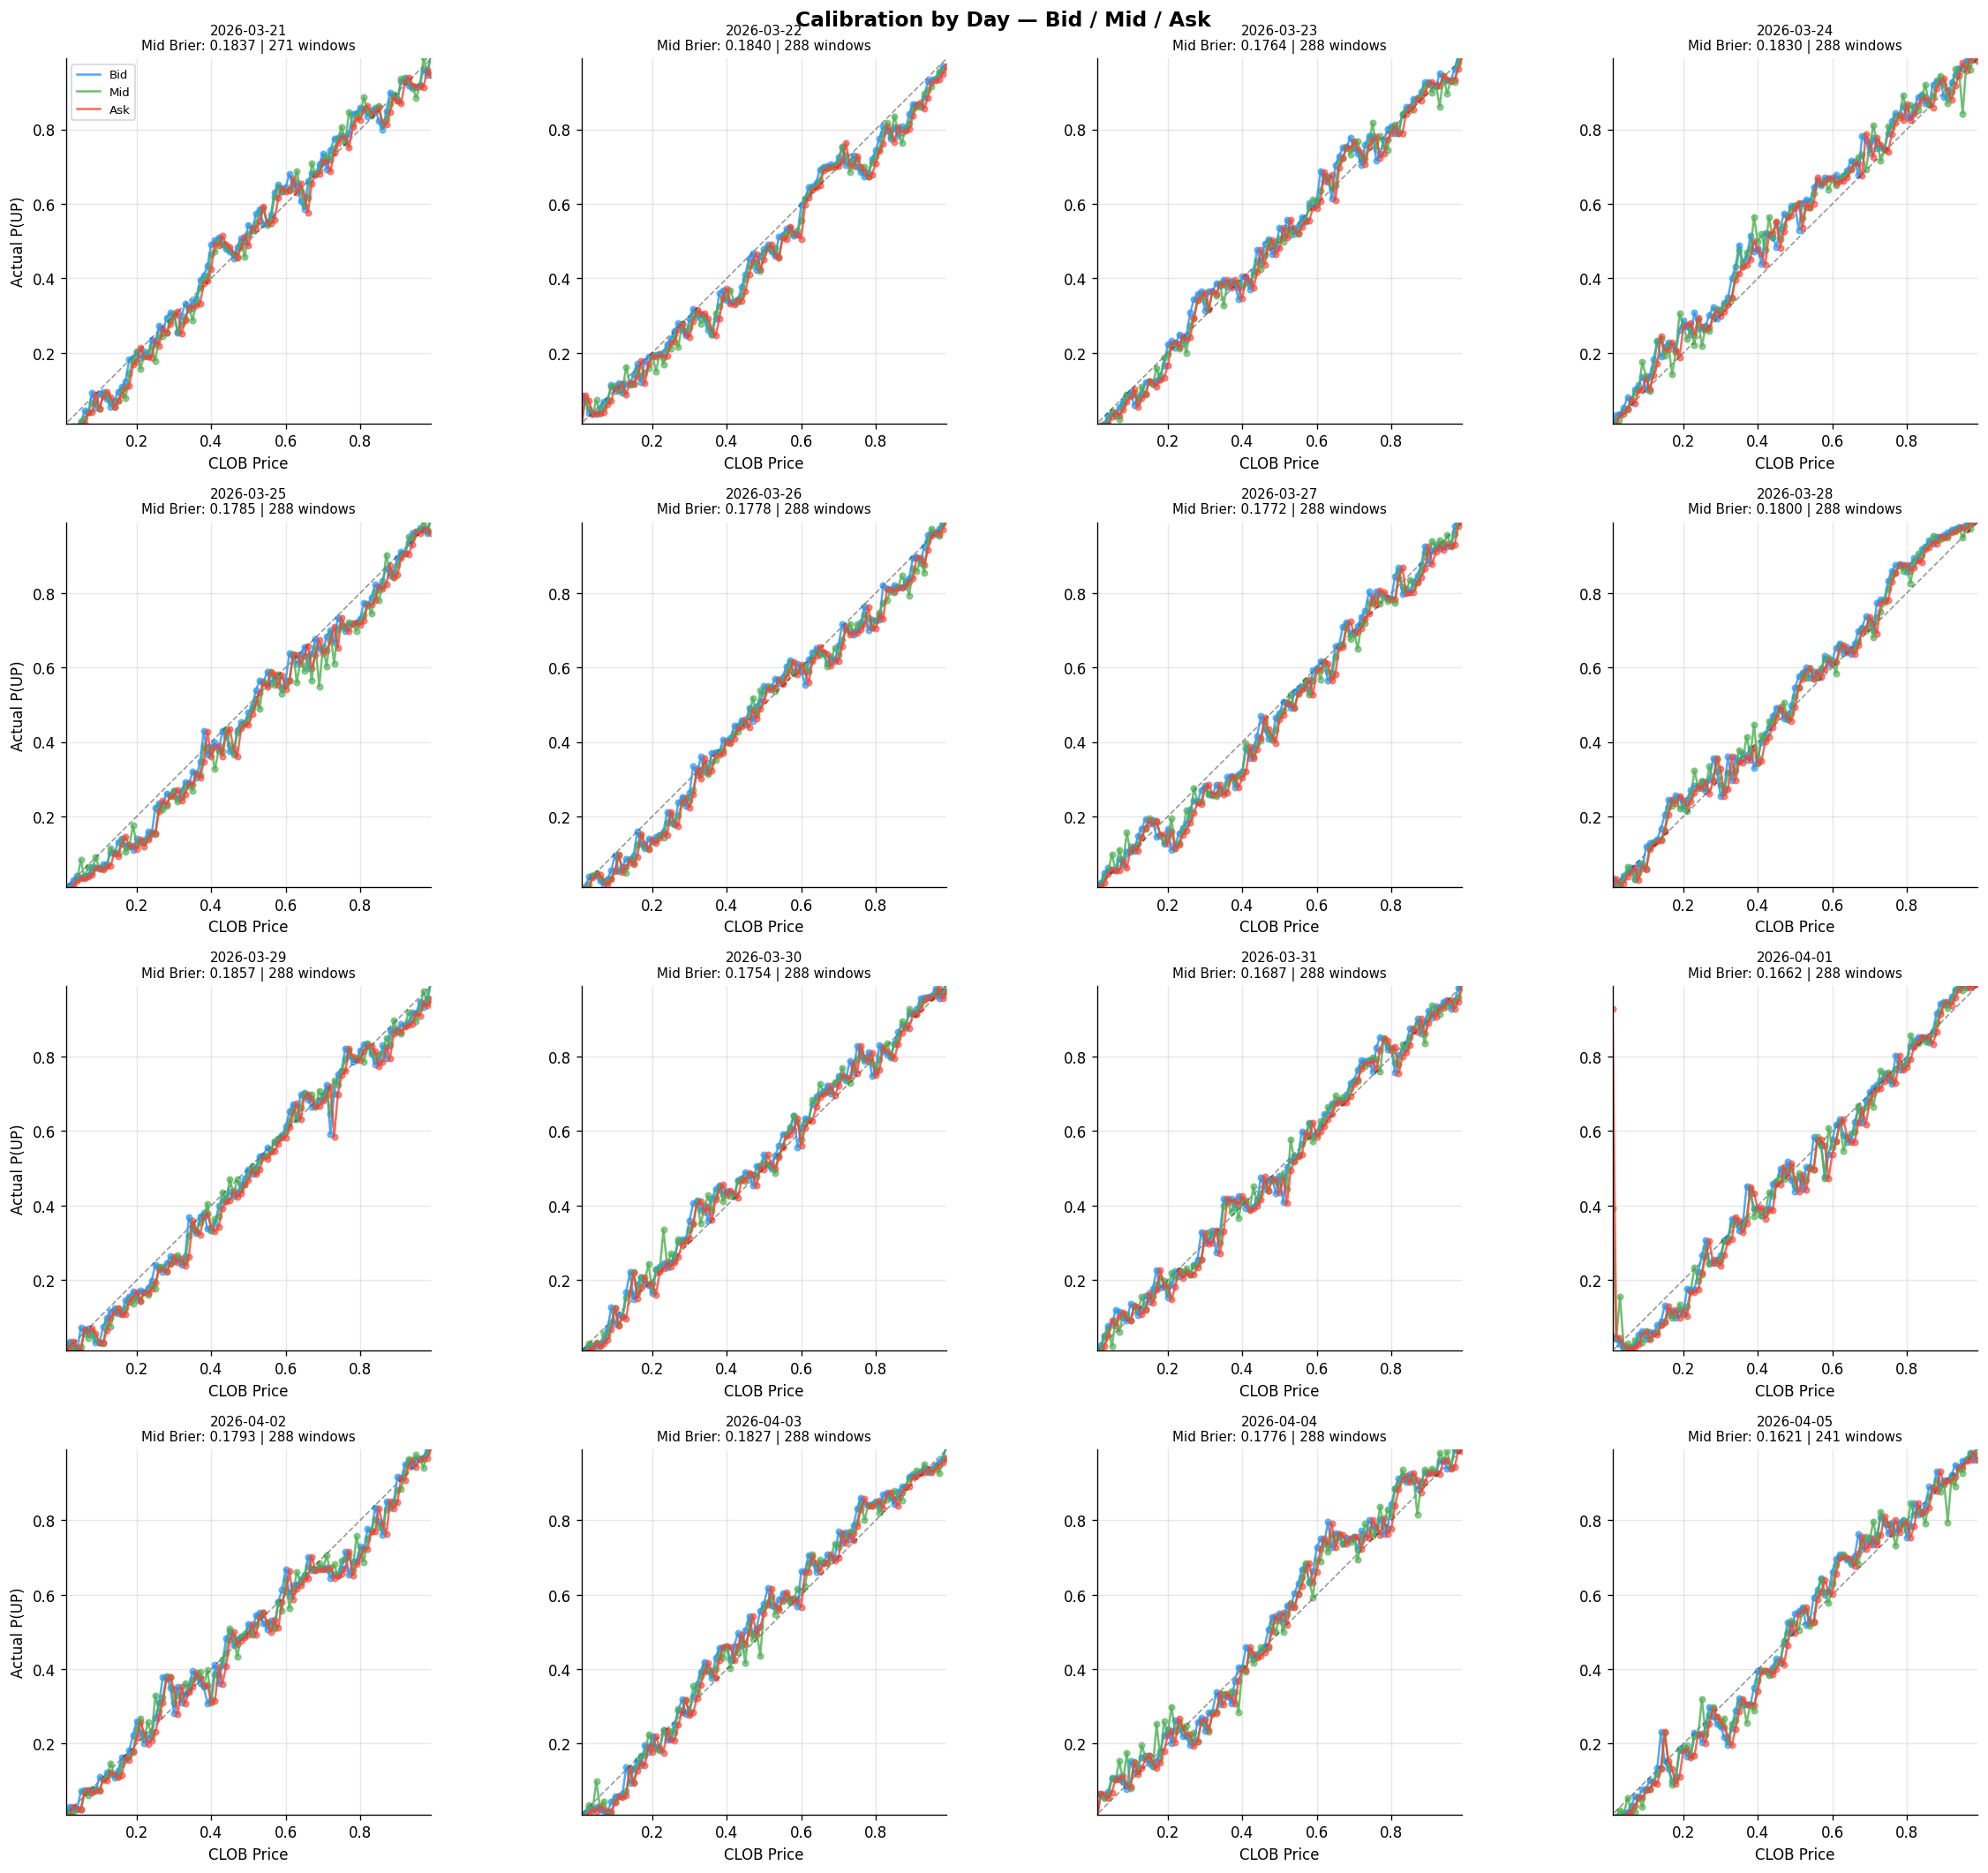

,windows,ticks,brier_bid,brier_mid,brier_ask,wmace_mid,up_frac,mean_spread
date,,,,,,,,
2026-03-21,271,758727,0.1838,0.1837,0.1837,2.8090,0.4982,0.0138
2026-03-22,288,779963,0.1836,0.1840,0.1845,3.9343,0.4792,0.0127
2026-03-23,288,771801,0.1765,0.1764,0.1764,2.1541,0.5174,0.0120
2026-03-24,288,782935,0.1838,0.1830,0.1823,4.9207,0.5486,0.0127
2026-03-25,288,786200,0.1782,0.1785,0.1789,3.4925,0.4826,0.0119
2026-03-26,288,784302,0.1776,0.1778,0.1782,2.9111,0.4757,0.0124
2026-03-27,288,779822,0.1770,0.1772,0.1776,3.2628,0.4757,0.0121
2026-03-28,288,818426,0.1803,0.1800,0.1798,3.0876,0.5208,0.0119
2026-03-29,288,816204,0.1855,0.1857,0.1861,3.0058,0.4861,0.0124


In [11]:
dates = sorted(bbo['date'].unique())
n = len(dates)
ncols = min(4, n)
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows))
axes = np.array(axes).flatten()
fig.suptitle('Calibration by Day — Bid / Mid / Ask', fontsize=14, fontweight='bold')

day_rows = []
for i, date in enumerate(dates):
    ax  = axes[i]
    d   = bbo[bbo['date'] == date]
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, lw=1)

    for col, lbl, col_ in zip(cols, labels, colors):
        ct = calibration_table(d, col)
        ax.plot(ct['price'], ct['actual_p'], c=col_, alpha=0.8, lw=1.5, label=lbl)
        ax.scatter(ct['price'], ct['actual_p'], s=15, c=col_, alpha=0.6)

    bs_mid = brier(d, 'mid')
    n_wins = d['window_ts'].nunique()
    ax.set_title(f'{date}\nMid Brier: {bs_mid:.4f} | {n_wins} windows', fontsize=9)
    ax.set_xlim(0.01, 0.99); ax.set_ylim(0.01, 0.99)
    ax.set_aspect('equal')
    if i == 0: ax.legend(fontsize=8)
    ax.set_xlabel('CLOB Price'); ax.set_ylabel('Actual P(UP)' if i % ncols == 0 else '')

    day_rows.append({'date': str(date), 'windows': n_wins, 'ticks': len(d),
                     'brier_bid': brier(d, 'best_bid'),
                     'brier_mid': brier(d, 'mid'),
                     'brier_ask': brier(d, 'best_ask'),
                     'wmace_mid': wmace(d, 'mid') * 100,
                     'up_frac':   d.groupby('window_ts')['outcome'].first().mean(),
                     'mean_spread': d['spread'].mean()})

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig('../figures/02_calibration_by_day.png', dpi=150, bbox_inches='tight')
plt.show()

day_df = pd.DataFrame(day_rows).set_index('date')
day_df.round(4)

## 9. Calibration by Window Phase

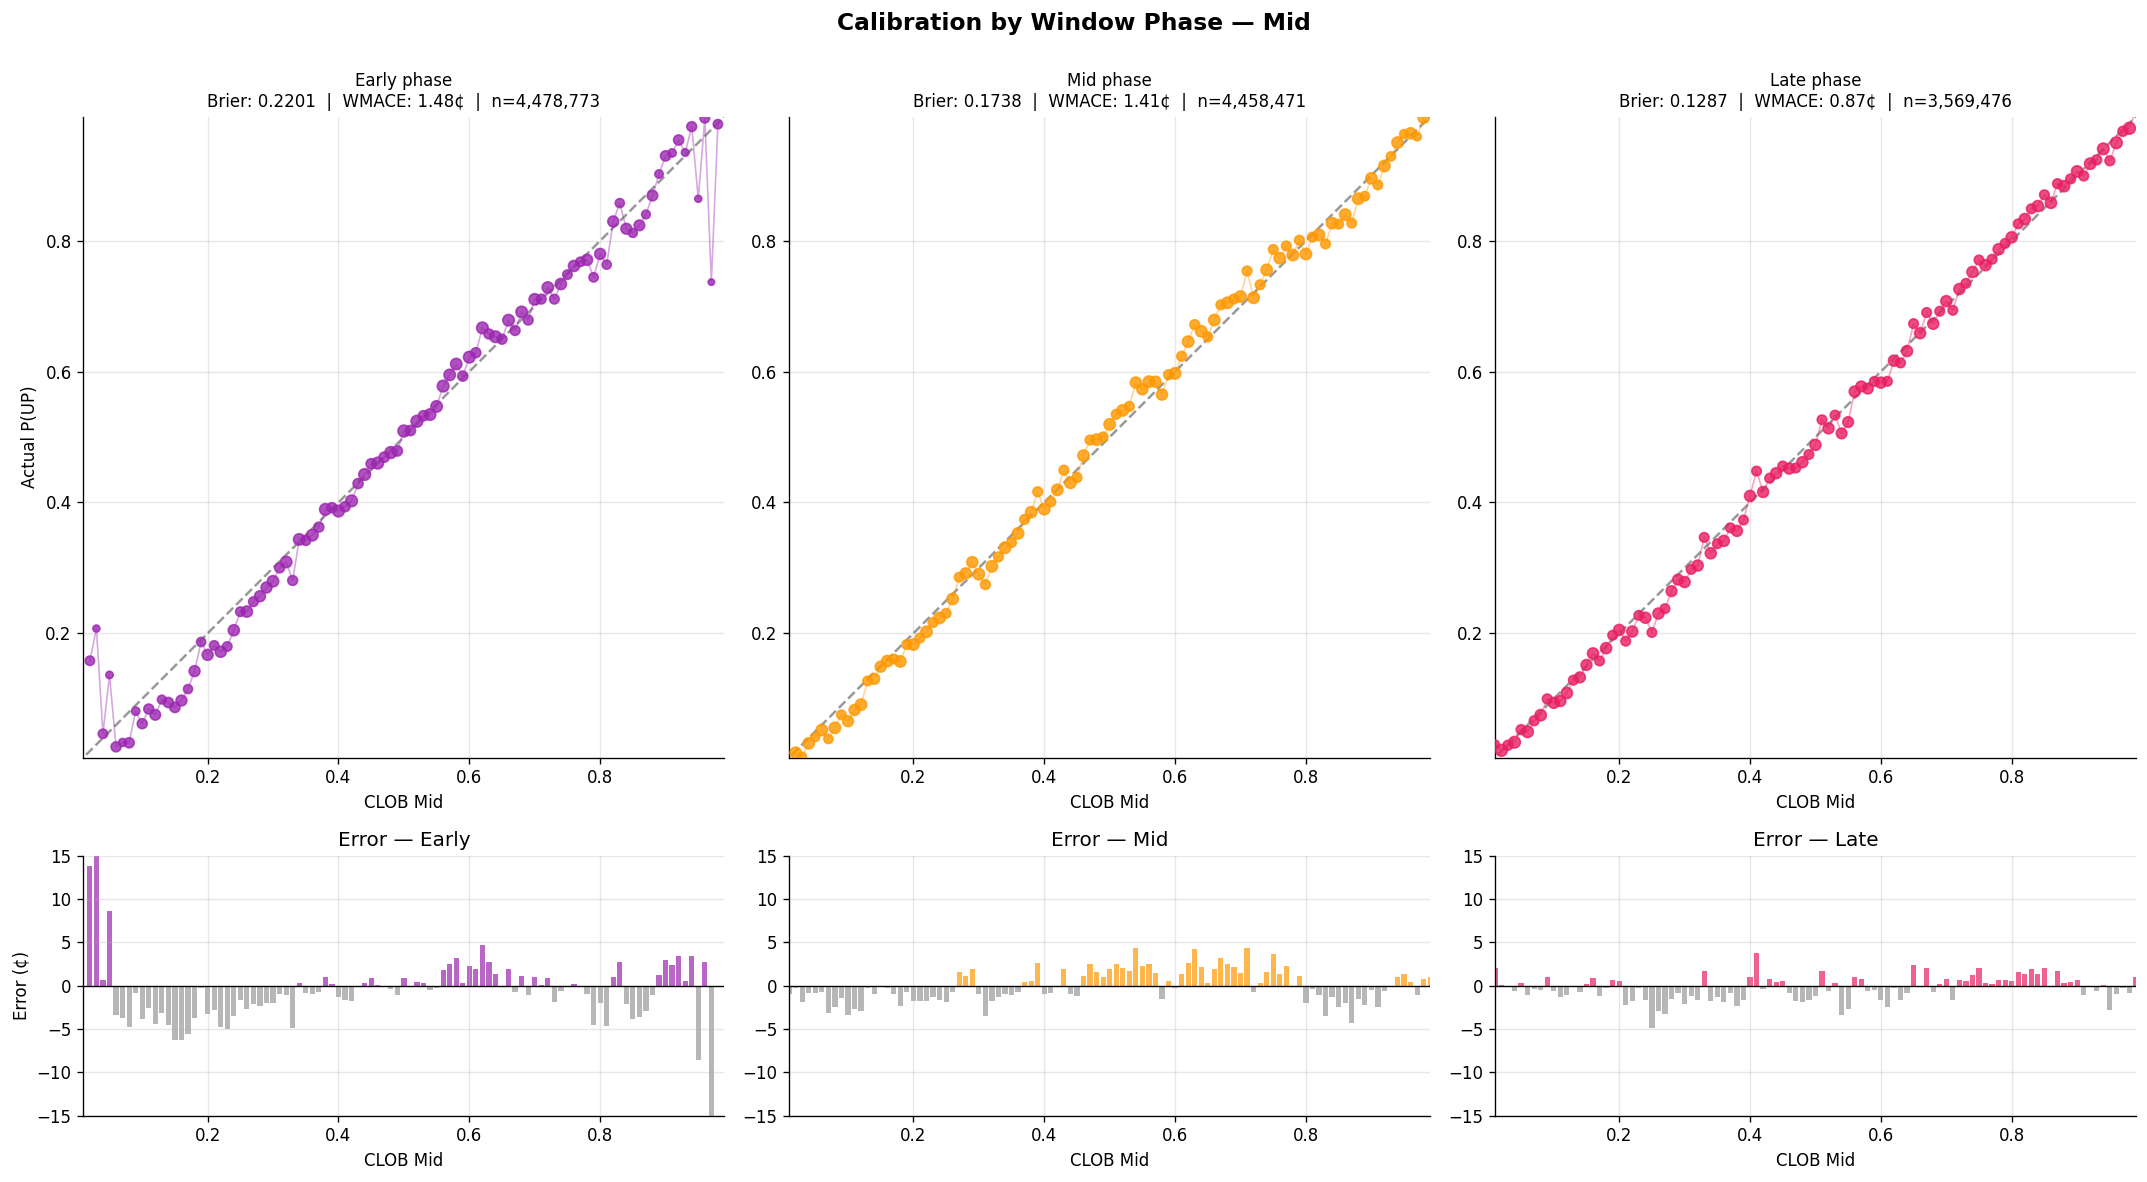


=== PHASE SUMMARY (Mid) ===
Early     n=4,478,773  Brier=0.2201  WMACE=1.48¢
Mid       n=4,458,471  Brier=0.1738  WMACE=1.41¢
Late      n=3,569,476  Brier=0.1287  WMACE=0.87¢


In [12]:
phases = ['Early', 'Mid', 'Late']
phase_colors = ['#9C27B0', '#FF9800', '#E91E63']

fig, axes = plt.subplots(2, 3, figsize=(18, 10),
                         gridspec_kw={'height_ratios': [3, 1]})
fig.suptitle('Calibration by Window Phase — Mid', fontsize=14, fontweight='bold')

for j, (phase, pcol) in enumerate(zip(phases, phase_colors)):
    ph = bbo[bbo['phase'] == phase]
    if len(ph) == 0:
        axes[0, j].set_title(f'{phase}\nNo data')
        continue

    ct = calibration_table(ph, 'mid')
    bs = brier(ph, 'mid')
    wm = wmace(ph, 'mid')

    ax = axes[0, j]
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, lw=1.5)
    sz = np.log1p(ct['count']) * 4
    ax.scatter(ct['price'], ct['actual_p'], s=sz, c=pcol, alpha=0.8, zorder=5)
    ax.plot(ct['price'], ct['actual_p'], c=pcol, alpha=0.4, lw=1)
    ax.set_title(f'{phase} phase\nBrier: {bs:.4f}  |  WMACE: {wm*100:.2f}¢  |  n={len(ph):,}', fontsize=10)
    ax.set_xlim(0.01, 0.99); ax.set_ylim(0.01, 0.99)
    ax.set_aspect('equal')
    ax.set_xlabel('CLOB Mid'); ax.set_ylabel('Actual P(UP)' if j == 0 else '')

    ax2 = axes[1, j]
    ax2.bar(ct['price'], ct['error'] * 100, width=0.008,
            color=[pcol if e >= 0 else '#999' for e in ct['error']], alpha=0.7)
    ax2.axhline(0, color='black', lw=0.8)
    ax2.set_xlim(0.01, 0.99); ax2.set_ylim(-15, 15)
    ax2.set_xlabel(f'CLOB Mid'); ax2.set_ylabel('Error (¢)' if j == 0 else '')
    ax2.set_title(f'Error — {phase}')

plt.tight_layout()
plt.savefig('../figures/02_calibration_by_phase.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n=== PHASE SUMMARY (Mid) ===')
for phase in phases:
    ph = bbo[bbo['phase'] == phase]
    print(f'{phase:8s}  n={len(ph):>8,}  Brier={brier(ph, "mid"):.4f}  WMACE={wmace(ph, "mid")*100:.2f}¢')

## 10. Calibration by Volatility Regime

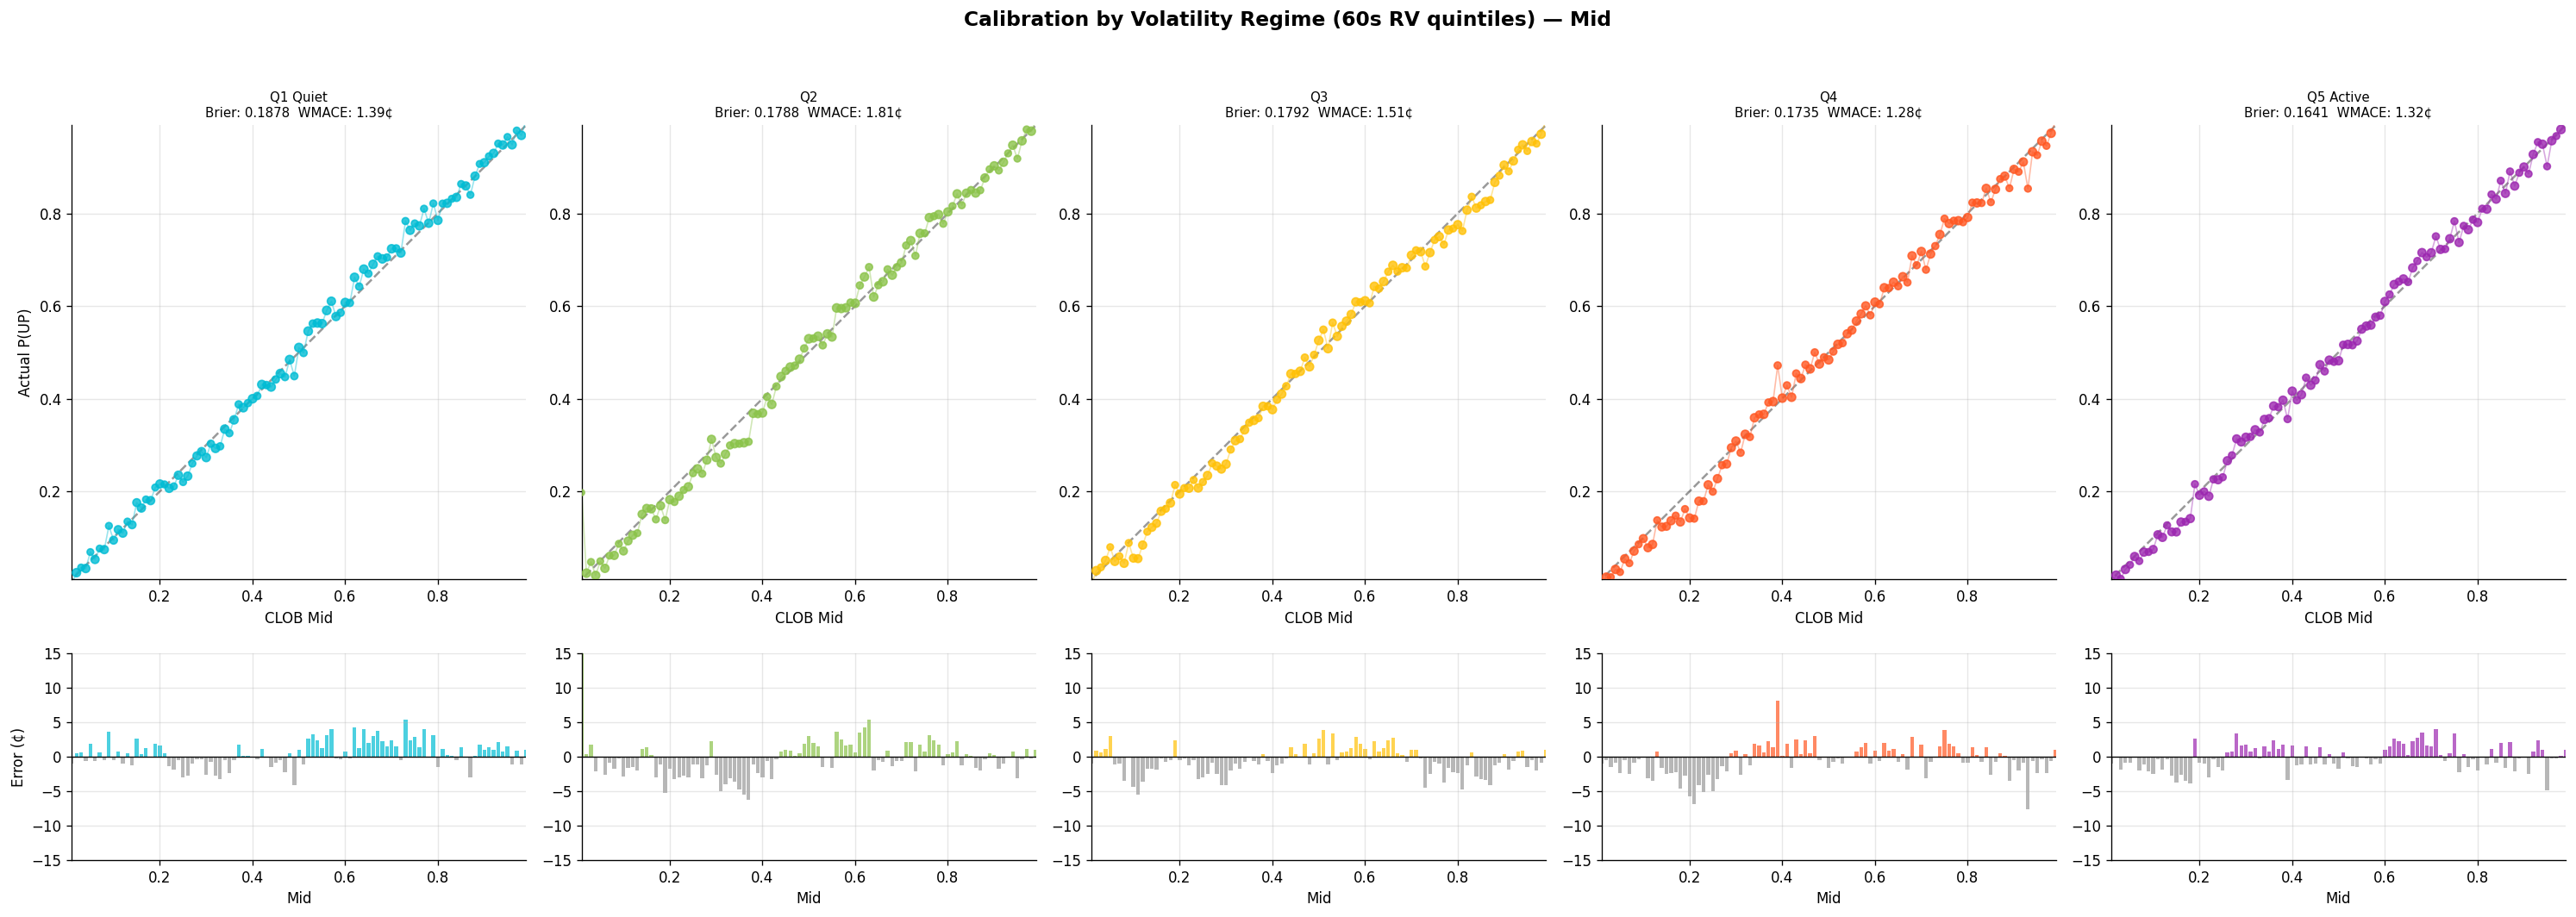


=== VOL REGIME SUMMARY (Mid) ===
Q1 Quiet      n=2,920,920  Brier=0.1878  WMACE=1.39¢
Q2            n=2,657,003  Brier=0.1788  WMACE=1.81¢
Q3            n=2,505,286  Brier=0.1792  WMACE=1.51¢
Q4            n=2,353,857  Brier=0.1735  WMACE=1.28¢
Q5 Active     n=2,069,654  Brier=0.1641  WMACE=1.32¢


In [13]:
quintiles  = ['Q1 Quiet', 'Q2', 'Q3', 'Q4', 'Q5 Active']
q_colors   = ['#00BCD4', '#8BC34A', '#FFC107', '#FF5722', '#9C27B0']

fig, axes = plt.subplots(2, 5, figsize=(25, 9),
                         gridspec_kw={'height_ratios': [3, 1]})
fig.suptitle('Calibration by Volatility Regime (60s RV quintiles) — Mid', fontsize=14, fontweight='bold')

for j, (q, qcol) in enumerate(zip(quintiles, q_colors)):
    qd = bbo[bbo['rv_q'] == q]
    if len(qd) < 100:
        axes[0, j].set_title(f'{q}\nInsufficient data'); continue

    ct = calibration_table(qd, 'mid')
    bs = brier(qd, 'mid')
    wm = wmace(qd, 'mid')

    ax = axes[0, j]
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, lw=1.5)
    sz = np.log1p(ct['count']) * 3
    ax.scatter(ct['price'], ct['actual_p'], s=sz, c=qcol, alpha=0.8, zorder=5)
    ax.plot(ct['price'], ct['actual_p'], c=qcol, alpha=0.4, lw=1)
    ax.set_title(f'{q}\nBrier: {bs:.4f}  WMACE: {wm*100:.2f}¢', fontsize=9)
    ax.set_xlim(0.01, 0.99); ax.set_ylim(0.01, 0.99)
    ax.set_aspect('equal')
    ax.set_xlabel('CLOB Mid'); ax.set_ylabel('Actual P(UP)' if j == 0 else '')

    ax2 = axes[1, j]
    ax2.bar(ct['price'], ct['error'] * 100, width=0.008,
            color=[qcol if e >= 0 else '#999' for e in ct['error']], alpha=0.7)
    ax2.axhline(0, color='black', lw=0.8)
    ax2.set_xlim(0.01, 0.99); ax2.set_ylim(-15, 15)
    ax2.set_xlabel('Mid'); ax2.set_ylabel('Error (¢)' if j == 0 else '')

plt.tight_layout()
plt.savefig('../figures/02_calibration_by_vol.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n=== VOL REGIME SUMMARY (Mid) ===')
for q in quintiles:
    qd = bbo[bbo['rv_q'] == q]
    if len(qd) > 0:
        print(f'{q:12s}  n={len(qd):>8,}  Brier={brier(qd, "mid"):.4f}  WMACE={wmace(qd, "mid")*100:.2f}¢')

## 11. Spread Analysis

The median spread is 1¢ (one tick) almost everywhere, so a median says nothing about where spreads are wider, and a
mean is pulled up by rare quotes spread far apart. The panels below use one measure throughout: the **share of time the
spread is wider than one tick**.

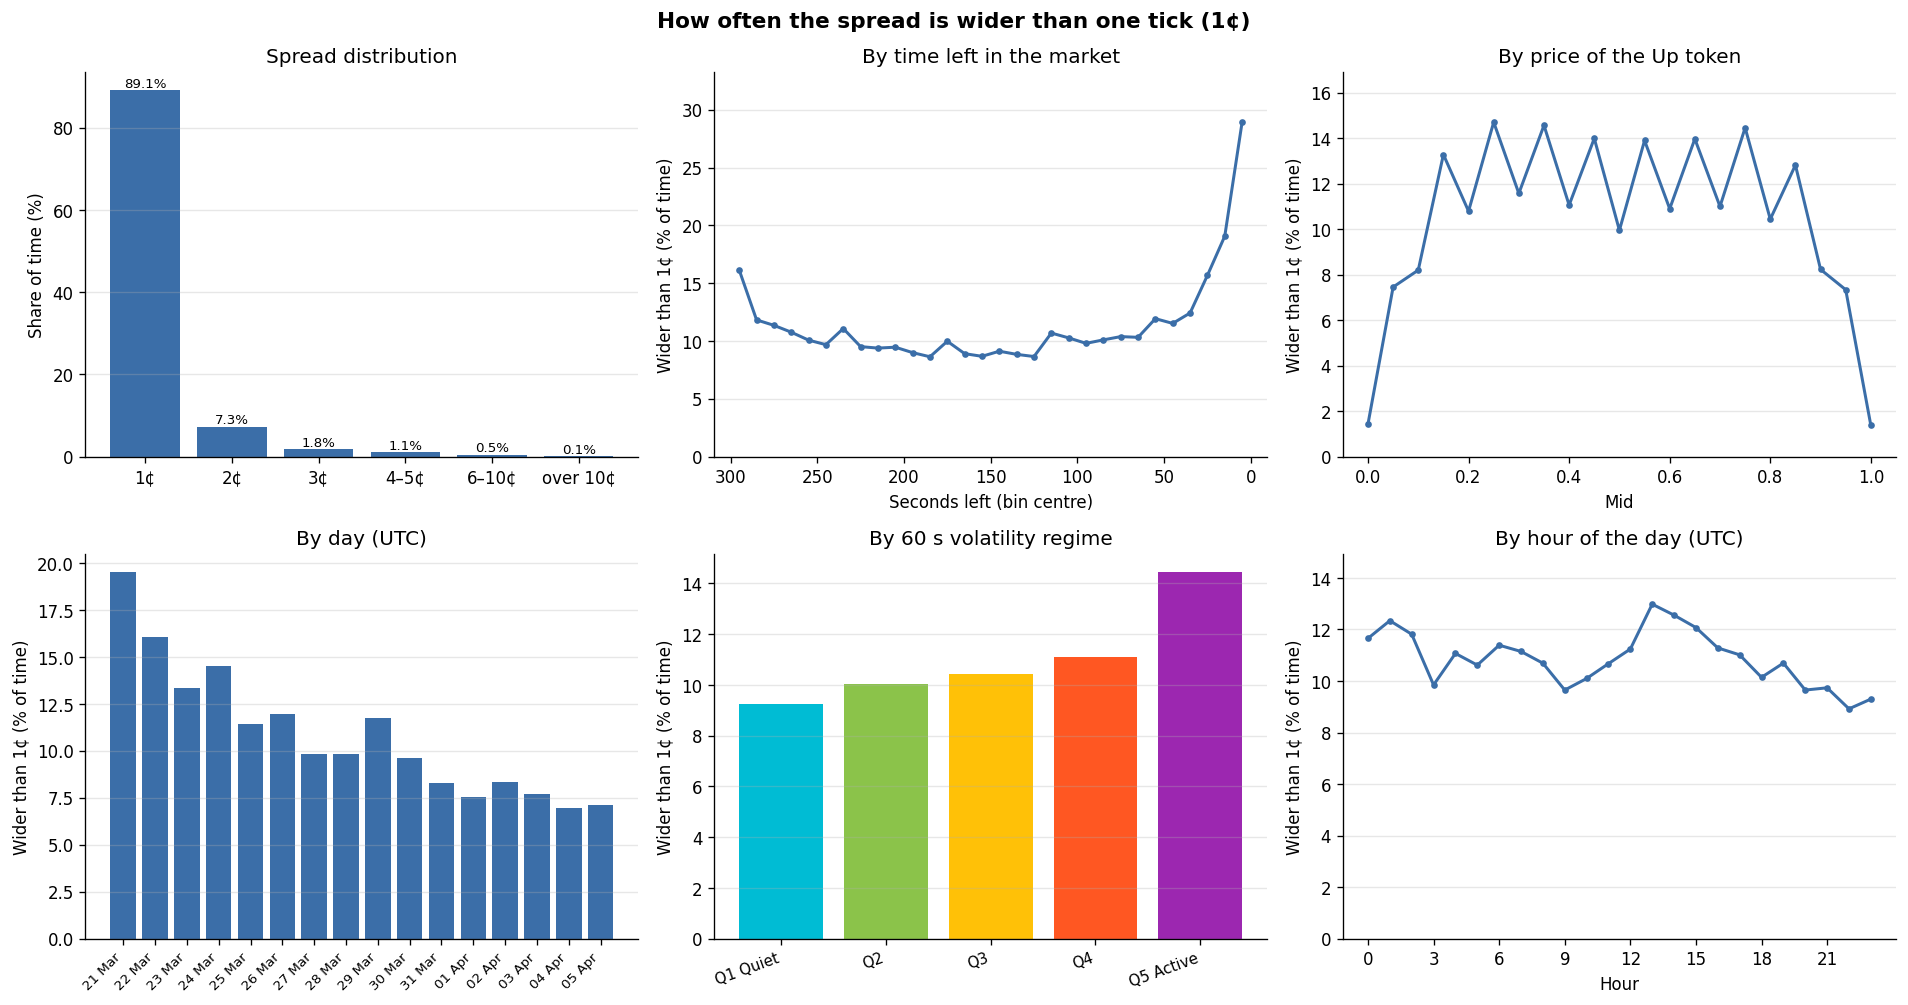

=== SPREAD SUMMARY ===
Median 1.00c   mean 1.20c   p95 2.00c   p99 4.00c
Share of time at each spread (%): {'1¢': 89.09, '2¢': 7.29, '3¢': 1.84, '4–5¢': 1.1, '6–10¢': 0.49, 'over 10¢': 0.15}
Wider than 1c overall: 10.9%
  by time left : lowest 8.6% (185.0), highest 28.9% (5.0)
  by mid       : lowest 1.4% (1.0), highest 14.7% (0.25)
  by day       : lowest 6.9% (2026-04-04), highest 19.5% (2026-03-21)
  by volatility: lowest 9.3% (Q1 Quiet), highest 14.4% (Q5 Active)
  by hour      : lowest 8.9% (22), highest 13.0% (13)
  first 10 s of a market: 16.1%   last 10 s: 28.9%


In [14]:
s_c = np.round(bbo['spread'].values * 100).astype(int)           # spread in whole ticks
bbo['wide'] = s_c > 1                                             # wider than one tick

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
fig.suptitle('How often the spread is wider than one tick (1¢)', fontsize=13, fontweight='bold')
C = '#3B6EA8'

# 1. Distribution: share of time at each spread
ax = axes[0, 0]
labels_s = ['1¢', '2¢', '3¢', '4–5¢', '6–10¢', 'over 10¢']
cuts = [0, 1, 2, 3, 5, 10, 100]
share_s = np.histogram(s_c, bins=np.array(cuts) + 0.5)[0] / len(s_c) * 100
ax.bar(labels_s, share_s, color=C)
for x_, v in enumerate(share_s):
    ax.text(x_, v, f'{v:.1f}%' if v >= 0.1 else f'{v:.2f}%', ha='center', va='bottom', fontsize=8)
ax.set_ylabel('Share of time (%)'); ax.set_title('Spread distribution')

def share_line(ax, groups, title, xlabel, invert=False):
    g = bbo.groupby(groups, observed=True)['wide'].agg(['mean', 'size'])
    s = g.loc[g['size'] >= 1000, 'mean'] * 100                     # groups with too few snapshots are left out
    ax.plot(s.index, s.values, color=C, lw=1.8, marker='o' if len(s) < 40 else None, ms=3)
    ax.set_ylim(0, max(5, s.max() * 1.15)); ax.set_title(title); ax.set_xlabel(xlabel)
    ax.set_ylabel('Wider than 1¢ (% of time)')
    if invert: ax.invert_xaxis()
    return s

# 2. Time remaining (10 s bins; a quote at exactly 300 s left goes into the 290-300 bin)
bbo['t_rem_bin10'] = np.minimum(bbo['t_rem'] // 10 * 10, 290) + 5
by_trem = share_line(axes[0, 1], 't_rem_bin10', 'By time left in the market', 'Seconds left (bin centre)', invert=True)

# 3. Mid price (bins of 0.05)
bbo['mid_bin20'] = np.round(bbo['mid'] * 20) / 20
by_mid = share_line(axes[0, 2], 'mid_bin20', 'By price of the Up token', 'Mid')

# 4. Day
ax = axes[1, 0]
by_day = bbo.groupby('date')['wide'].mean() * 100
ax.bar(range(len(by_day)), by_day.values, color=C)
ax.set_xticks(range(len(by_day)))
ax.set_xticklabels([pd.Timestamp(d).strftime('%d %b') for d in by_day.index], rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Wider than 1¢ (% of time)'); ax.set_title('By day (UTC)')

# 5. Volatility regime
ax = axes[1, 1]
by_vol = (bbo.groupby('rv_q', observed=True)['wide'].mean() * 100).reindex(quintiles)
ax.bar(range(len(by_vol)), by_vol.values, color=q_colors)
ax.set_xticks(range(len(by_vol))); ax.set_xticklabels(quintiles, rotation=20, ha='right', fontsize=9)
ax.set_ylabel('Wider than 1¢ (% of time)'); ax.set_title('By 60 s volatility regime')

# 6. Hour of day
ax = axes[1, 2]
bbo['hour_utc'] = (bbo['local_ms'] // 3_600_000) % 24
by_hour = share_line(ax, 'hour_utc', 'By hour of the day (UTC)', 'Hour')
ax.set_xticks(range(0, 24, 3))

for a in axes.flat:
    a.grid(axis='x', visible=False)
plt.tight_layout()
plt.savefig('../figures/02_spread_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print('=== SPREAD SUMMARY ===')
print(f'Median {bbo["spread"].median()*100:.2f}c   mean {bbo["spread"].mean()*100:.2f}c   '
      f'p95 {bbo["spread"].quantile(0.95)*100:.2f}c   p99 {bbo["spread"].quantile(0.99)*100:.2f}c')
print('Share of time at each spread (%):', {k: round(float(v), 2) for k, v in zip(labels_s, share_s)})
print(f'Wider than 1c overall: {bbo["wide"].mean():.1%}')
for name, s in [('time left', by_trem), ('mid', by_mid), ('day', by_day), ('volatility', by_vol), ('hour', by_hour)]:
    print(f'  by {name:<10}: lowest {s.min():.1f}% ({s.idxmin()}), highest {s.max():.1f}% ({s.idxmax()})')
print(f'  first 10 s of a market: {bbo.loc[bbo["t_rem"] > 290, "wide"].mean():.1%}   '
      f'last 10 s: {bbo.loc[bbo["t_rem"] <= 10, "wide"].mean():.1%}')

## 12. Brier Heatmap — Phase × Volatility

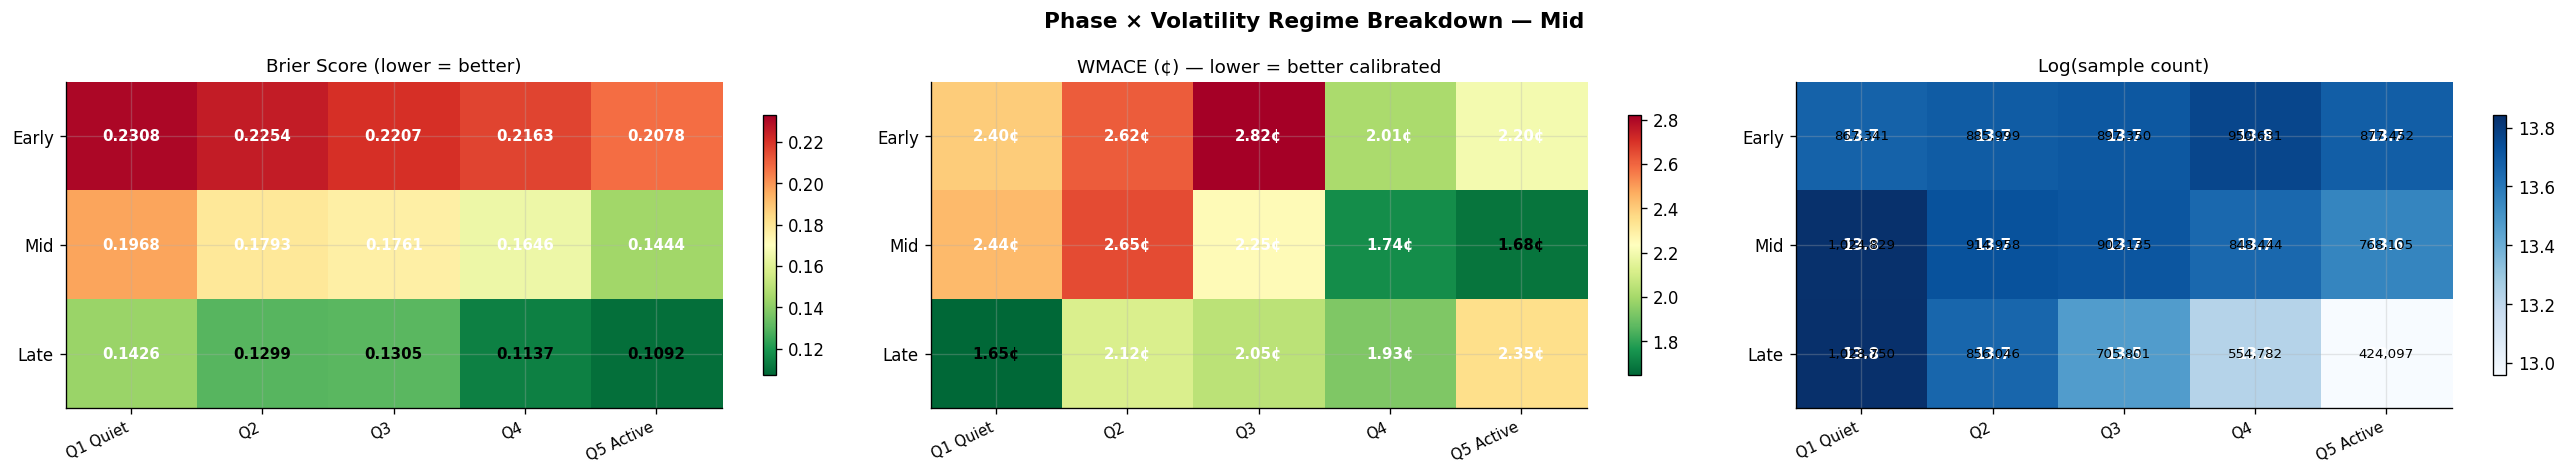

In [15]:
brier_grid  = np.full((len(phases), len(quintiles)), np.nan)
wmace_grid  = np.full((len(phases), len(quintiles)), np.nan)
count_grid  = np.zeros((len(phases), len(quintiles)))

for i, ph in enumerate(phases):
    for j, q in enumerate(quintiles):
        sub = bbo[(bbo['phase'] == ph) & (bbo['rv_q'] == q)]
        if len(sub) >= 200:
            brier_grid[i, j] = brier(sub, 'mid')
            wmace_grid[i, j] = wmace(sub, 'mid') * 100
            count_grid[i, j] = len(sub)

fig, axes = plt.subplots(1, 3, figsize=(22, 4))
fig.suptitle('Phase × Volatility Regime Breakdown — Mid', fontsize=13, fontweight='bold')

def annotated_heatmap(ax, data, title, fmt, cmap, vmin=None, vmax=None):
    im = ax.imshow(data, cmap=cmap, aspect='auto', vmin=vmin, vmax=vmax)
    plt.colorbar(im, ax=ax, shrink=0.8)
    ax.set_xticks(range(len(quintiles)))
    ax.set_xticklabels(quintiles, rotation=25, ha='right', fontsize=9)
    ax.set_yticks(range(len(phases)))
    ax.set_yticklabels(phases)
    ax.set_title(title, fontsize=11)
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            if not np.isnan(data[i, j]):
                ax.text(j, i, fmt.format(data[i, j]),
                        ha='center', va='center', fontsize=9, fontweight='bold',
                        color='white' if data[i, j] > (np.nanmax(data) * 0.6) else 'black')

annotated_heatmap(axes[0], brier_grid,
                  'Brier Score (lower = better)', '{:.4f}', 'RdYlGn_r',
                  vmin=np.nanmin(brier_grid)*0.98, vmax=np.nanmax(brier_grid)*1.01)

annotated_heatmap(axes[1], wmace_grid,
                  'WMACE (¢) — lower = better calibrated', '{:.2f}¢', 'RdYlGn_r')

annotated_heatmap(axes[2], count_grid,
                  'Snapshots per cell', '{:,.0f}', 'Blues')

plt.tight_layout()
plt.savefig('../figures/02_brier_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. How steep is the market's price as time runs out?

For each 50 s slice of the window (and the last 15 s), a logistic curve `P(Up) = 1 / (1 + exp(-(a + k·x)))` is fitted to
the Polymarket mid against `x`, the Binance move in dollars since the market opened. `k` is the steepness: how fast the
price goes towards 0 or 1 for each dollar BTC moves. One snapshot per second per market is used.

These curves describe the market's own price, not the outcome.

Snapshots: 1,266,254 from 4,544 markets, 21 March to 05 April 2026 UTC
    slice      n      a  k_per_usd  mean_abs_error_c  p_up_at_plus_50usd  p_up_at_minus_50usd
   0-50 s 226521 0.0084     0.0180            4.9012              0.7125               0.2910
 50-100 s 227064 0.0175     0.0219            5.6689              0.7527               0.2539
100-150 s 226576 0.0201     0.0266            6.2126              0.7938               0.2129
150-200 s 223320 0.0152     0.0339            6.6919              0.8470               0.1570
200-250 s 210162 0.0189     0.0460            7.4430              0.9103               0.0929
250-300 s 152611 0.0216     0.0712           11.2020              0.9729               0.0283
last 15 s  31868 0.0294     0.1002           14.5730              0.9936               0.0068


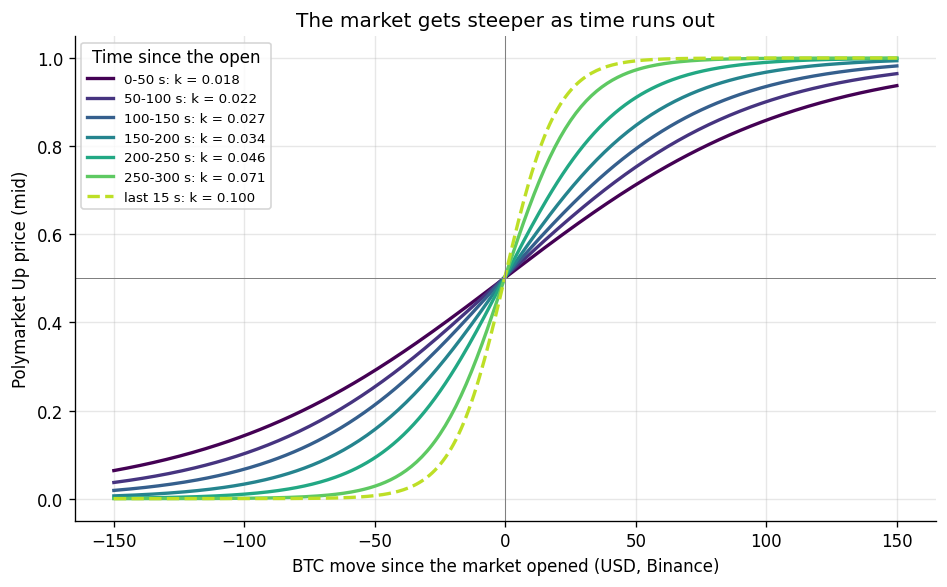

In [17]:
from scipy.optimize import curve_fit

SLICES = [(0, 50), (50, 100), (100, 150), (150, 200), (200, 250), (250, 300), (285, 300)]   # seconds since the open

st = bbo[['local_ms', 'mid', 't_rem', 'window_ts']].copy()
st['sec'] = st['local_ms'] // 1000
st = st.drop_duplicates('sec').reset_index(drop=True)       # one snapshot per second (the first of each second)
bn_ms, bn_px = bn['local_ms'].to_numpy(np.int64), bn['price'].to_numpy(float)
i_now  = np.searchsorted(bn_ms, st['local_ms'].to_numpy(np.int64), side='right') - 1
i_open = np.searchsorted(bn_ms, st['window_ts'].to_numpy(np.int64) * 1000, side='right') - 1
ok = (i_now >= 0) & (i_open >= 0)
st = st[ok].reset_index(drop=True)
st['x'] = bn_px[i_now[ok]] - bn_px[i_open[ok]]
st['elapsed'] = 300 - st['t_rem']

def logistic(x, a, k):
    return 1 / (1 + np.exp(-(a + k * x)))

print(f"Snapshots: {len(st):,} from {st['window_ts'].nunique():,} markets, "
      f"{pd.to_datetime(st['local_ms'].min(), unit='ms'):%d %B} to {pd.to_datetime(st['local_ms'].max(), unit='ms'):%d %B %Y} UTC")
fits = []
for lo, hi in SLICES:
    s = st[(st['elapsed'] >= lo) & (st['elapsed'] < hi)]
    (a, k), _ = curve_fit(logistic, s['x'].to_numpy(), s['mid'].to_numpy(), p0=(0.0, 0.02))
    err = np.abs(logistic(s['x'].to_numpy(), a, k) - s['mid'].to_numpy()).mean() * 100
    label = 'last 15 s' if (lo, hi) == (285, 300) else f'{lo}-{hi} s'
    fits.append({'slice': label, 'n': len(s), 'a': a, 'k_per_usd': k, 'mean_abs_error_c': err,
                 'p_up_at_plus_50usd': logistic(50, a, k), 'p_up_at_minus_50usd': logistic(-50, a, k)})
fits = pd.DataFrame(fits)
print(fits.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
xs = np.linspace(-150, 150, 301)
cols = plt.cm.viridis(np.linspace(0, 0.9, len(fits)))
for (_, r), c in zip(fits.iterrows(), cols):
    ax.plot(xs, logistic(xs, r['a'], r['k_per_usd']), color=c, lw=2, ls='--' if r['slice'] == 'last 15 s' else '-',
            label=f"{r['slice']}: k = {r['k_per_usd']:.3f}")
ax.axhline(0.5, color='grey', lw=0.6); ax.axvline(0, color='grey', lw=0.6)
ax.set_xlabel('BTC move since the market opened (USD, Binance)'); ax.set_ylabel('Polymarket Up price (mid)')
ax.set_title('The market gets steeper as time runs out'); ax.legend(title='Time since the open', fontsize=8)
plt.tight_layout(); plt.savefig('../figures/02_market_steepness.png', dpi=150, bbox_inches='tight'); plt.show()

## Reading the results

* **The market's mid-price is well calibrated overall** (pooled, 16 days): mid Brier 0.1775, weighted mean calibration
  error 0.97¢; bid and ask are within 0.2¢ of that. The calibration curve hugs the diagonal. The deviations in the
  lower panels of the first figure look patterned (below about 0.4 the outcome frequency is mostly 1 to 3¢ under the
  price, between about 0.5 and 0.8 mostly up to 3¢ over it), but with intervals from resampling windows none of it is
  distinguishable from noise: pooled, below 0.40 it is −1.15¢ (−2.49 to +0.22) and from 0.50 to 0.80 +1.09¢ (−0.66 to
  +2.66), and 7 of 91 price levels have an interval that excludes zero, close to the 4 or 5 expected by chance.
* **The score is dominated by *when* in the window you look:** early (200 s or more left) Brier 0.2201, close to
  the 0.25 of an uninformed 50/50; mid 0.1738; late (under 100 s left) 0.1287.
* By volatility regime the mid's Brier ranges from 0.1878 (quietest quintile) to 0.1641 (most active).
* Median bid-ask spread is 1.00¢ (the tick size), mean 1.20¢, 95th percentile 2.00¢. The median is exactly 1¢ for every
  day, volatility regime, mid-price bucket and 10-second slice of the window. The spread is wider than one tick 10.9% of the
  time overall, 16.1% in the first 10 seconds of a window and 28.9% in its last 10 seconds (section 11).
* Per-day mid Brier ranges from 0.1621 to 0.1857 (see the table in section 8; 21 March and 5 April are partial days,
  with 271 and 241 windows).
* `windows.csv` lists 4,698 windows, starting at 12:35 UTC on 20 March, but the order-book capture only starts in the
  early hours of 21 March. The 154 earlier windows have no snapshots, so 4,544 windows enter the analysis.
* **The market gets steeper as time runs out** (section 13). The logistic steepness `k` rises from 0.018 per dollar in
  the first 50 s to 0.071 in the last 50 s and 0.100 in the last 15 s, so a $50 move takes the Up price to about 0.71
  early on, 0.97 in the last 50 s and 0.99 in the last 15 s. The fits get worse late in the window (mean error 4.9¢ in
  the first 50 s, 11.2¢ in the last 50 s, 14.6¢ in the last 15 s), because late prices jump towards 0 or 1.
* **What this does not show:** whether a model can beat this price. Good calibration is necessary but not sufficient
  for an efficient price.